## Aligning world-landmark hand model with holistic hand model

In [125]:
import os
import glob
import pandas as pd

curfolder = os.getcwd()
processedfolder = os.path.join(curfolder, 'Output_Timeseries')


In [126]:
outputcsv = glob.glob(os.path.join(processedfolder, '*.csv'))  # Ensure outtputf_ts is defined
outputcsv

['e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_ACCORDEON_308_body.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_ACCORDEON_308_hands.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\flipped_IP06_02_ABHOLEN.mp4_body.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_A-LITTLE_637_body.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_A-LITTLE_637_hands.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP02_(AUF)PUMPEN.mp4_body.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_A-LOT_626_body.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_A-LOT_626_hands.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP02_(AUF)PUMPEN.mp4_hands.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_AMBULANCE_480_body.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_AMBULANCE_480_hands.csv',
 'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\flipped_IP06_02_AB

In [141]:
worldfiles = [x for x in outputcsv if 'hands_world' in x]
pxfiles = [x for x in outputcsv if 'hands_hol' in x]


# Getting worldlandmark files into common format

In [128]:
sample = pd.read_csv(worldfiles[50])  # Example file for reference
worldfiles[50]

'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GtST_DGS_MOBILE-PHONE_130.mp4_hands_world.csv'

In [129]:

# Get rid of all rows where is only NAN
sample = sample.dropna(how='all')
# Reset index
sample = sample.reset_index(drop=True)

# Make hand column simple left/right
sample['hand'] = sample['hand'].str.extract(r'label:\s*"([^"]+)"')[0]
# Get the name of the columns
hand_cols = sample.columns[4:]
hand_cols

# Make an empty df with column time + hand_cols that are combined with both _LEFT adnd _RIGHT

# to each hand_cols, add both _LEFT and _RIGHT
df = pd.DataFrame(columns=['time'])

for i in range(len(hand_cols)):
    newcolname_right = hand_cols[i] + '_RIGHT'
    newcolname_left = hand_cols[i] + '_LEFT'
    df[newcolname_right] = None
    df[newcolname_left] = None


C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\939217658.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[newcolname_left] = None
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\939217658.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[newcolname_right] = None
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\939217658.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once

In [130]:
for i in range(len(sample)):
    df.loc[i, 'time'] = sample.loc[i, 'time']
    if sample.loc[i, 'hand'] == 'Right':
        for col in hand_cols:
            #print(sample.loc[i, col])
            df.loc[i, col + '_RIGHT'] = sample.loc[i, col]
            #df.loc[i, col + '_LEFT'] = None
    elif sample.loc[i, 'hand'] == 'Left':
        for col in hand_cols:
            df.loc[i, col + '_LEFT'] = sample.loc[i, col]
            #df.loc[i, col + '_RIGHT'] = None
    else:
        print(f"Unknown hand label at index {i}: {sample.loc[i, 'hand']}")

# Some rows are with repeating time, but have either only left or only right - merge those
df = df.groupby('time').first().reset_index()
    

In [131]:
df_interp = df.copy()
# interpolate missing values
for col in df_interp.columns[1:]:
    # interpolate
    df_interp[col] = df_interp[col].interpolate(method='linear', x=df_interp['time'], limit_direction='both') \
                 .fillna(method='bfill') \
                 .fillna(method='ffill')

C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\2839632694.py:5: FutureWarning: Series.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_interp[col] = df_interp[col].interpolate(method='linear', x=df_interp['time'], limit_direction='both') \
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\2839632694.py:6: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method='bfill') \
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\2839632694.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(method='bfill') \
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\2839632694.py:7

In [ ]:
GtST_DGS_MOBILE-PHONE_130

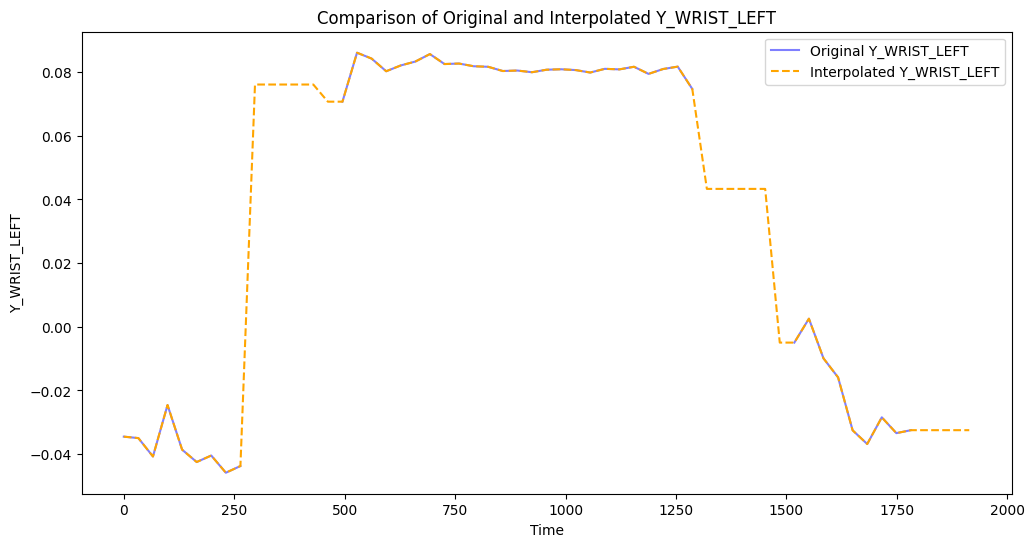

In [133]:
# plot X_WRIST_RIGHT from df and df_interp
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(df['time'], df['Y_WRIST_LEFT'], label='Original Y_WRIST_LEFT', color='blue', alpha=0.5)
plt.plot(df_interp['time'], df_interp['Y_WRIST_LEFT'], label='Interpolated Y_WRIST_LEFT', color='orange', linestyle='--')
plt.xlabel('Time')
plt.ylabel('Y_WRIST_LEFT')
plt.title('Comparison of Original and Interpolated Y_WRIST_LEFT')
plt.legend()
plt.show()

In [109]:
df

,time,X_WRIST_RIGHT,X_WRIST_LEFT,Y_WRIST_RIGHT,Y_WRIST_LEFT,Z_WRIST_RIGHT,Z_WRIST_LEFT,X_THUMB_CMC_RIGHT,X_THUMB_CMC_LEFT,Y_THUMB_CMC_RIGHT,...,Y_PINKY_DIP_RIGHT,Y_PINKY_DIP_LEFT,Z_PINKY_DIP_RIGHT,Z_PINKY_DIP_LEFT,X_PINKY_TIP_RIGHT,X_PINKY_TIP_LEFT,Y_PINKY_TIP_RIGHT,Y_PINKY_TIP_LEFT,Z_PINKY_TIP_RIGHT,Z_PINKY_TIP_LEFT
0,0,0.027075,-0.021573,-0.001105,-0.001740,0.055530,0.062717,0.011575,-0.012841,-0.013631,...,0.010864,0.010117,0.026248,0.005155,-0.018620,0.050504,0.006080,0.011518,0.033839,0.004391
1,40,0.034672,-0.021573,0.000295,-0.001740,0.056698,0.062717,0.016022,-0.012841,-0.013147,...,0.013469,0.010117,0.020936,0.005155,-0.020465,0.050504,0.010178,0.011518,0.027591,0.004391
2,80,0.033738,-0.021573,-0.002027,-0.001740,0.052660,0.062717,0.016420,-0.012841,-0.014523,...,0.014443,0.010117,0.012047,0.005155,-0.019760,0.050504,0.009727,0.011518,0.017844,0.004391
3,120,0.037802,-0.021573,-0.000879,-0.001740,0.054542,0.062717,0.018066,-0.012841,-0.014789,...,0.014418,0.010117,0.017259,0.005155,-0.020594,0.050504,0.010000,0.011518,0.022218,0.004391
4,160,0.031975,-0.021573,0.000450,-0.001740,0.054353,0.062717,0.014409,-0.012841,-0.012249,...,0.013455,0.010117,0.013508,0.005155,-0.019370,0.050504,0.008945,0.011518,0.018884,0.004391
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,3800,0.058968,-0.041202,0.016706,0.041022,0.026057,0.079516,0.042217,-0.023158,-0.004228,...,0.036501,0.017797,0.007382,0.028924,-0.045018,0.007176,0.041285,0.018513,0.012490,0.045267
96,3840,0.066062,-0.048838,0.014526,0.042240,0.021752,0.077146,0.049531,-0.029431,-0.008418,...,0.039776,0.023225,0.008069,0.022906,-0.044809,0.007245,0.044338,0.021722,0.013063,0.038848
97,3880,0.057187,-0.048727,0.015158,0.040332,0.042614,0.077817,0.037821,-0.027652,-0.007161,...,0.038031,0.027613,0.003809,0.025072,-0.040072,0.010542,0.042356,0.026392,0.008578,0.040187
98,3920,0.060968,-0.046229,0.017195,0.041562,0.054095,0.079608,0.038011,-0.026813,-0.005720,...,0.038206,0.032101,0.002336,0.022748,-0.040088,0.012260,0.041811,0.031465,0.005862,0.037540


In [147]:
# find this flipped_IP06_02_AKKORDEON in pxfiles
pxfile = pxfiles[1]

sample_px = pd.read_csv(pxfile)



In [148]:
sample_px

,time,X_LEFT_WRIST,Y_LEFT_WRIST,Z_LEFT_WRIST,X_LEFT_THUMB_CMC,Y_LEFT_THUMB_CMC,Z_LEFT_THUMB_CMC,X_LEFT_THUMB_MCP,Y_LEFT_THUMB_MCP,Z_LEFT_THUMB_MCP,...,Z_RIGHT_PINKY_FINGER_MCP,X_RIGHT_PINKY_FINGER_PIP,Y_RIGHT_PINKY_FINGER_PIP,Z_RIGHT_PINKY_FINGER_PIP,X_RIGHT_PINKY_FINGER_DIP,Y_RIGHT_PINKY_FINGER_DIP,Z_RIGHT_PINKY_FINGER_DIP,X_RIGHT_PINKY_FINGER_TIP,Y_RIGHT_PINKY_FINGER_TIP,Z_RIGHT_PINKY_FINGER_TIP
0,0.0,0.501839,0.737044,2.964327e-08,0.487128,0.748960,0.001572,0.479741,0.767722,0.001312,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.0,0.451737,0.736878,1.143088e-07,0.464393,0.745850,0.000153,0.473089,0.764193,-0.002498,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,20.0,0.502532,0.737418,5.354515e-08,0.487870,0.747731,0.001280,0.480119,0.764962,0.001294,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,20.0,0.448679,0.732530,1.376813e-07,0.461934,0.741405,0.000563,0.470681,0.760146,-0.001881,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,40.0,0.501979,0.738110,5.875085e-08,0.487881,0.747316,0.000944,0.480378,0.764783,0.000880,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
419,4440.0,0.446643,0.724765,7.910695e-08,0.459043,0.723100,-0.001286,0.468814,0.737106,-0.002578,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
420,4460.0,0.507154,0.730960,7.238795e-08,0.491591,0.733331,0.000769,0.481550,0.746574,-0.000264,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
421,4460.0,0.444963,0.721385,9.046002e-08,0.458665,0.721374,-0.000773,0.468604,0.736366,-0.001958,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
422,4480.0,0.507447,0.730749,6.990551e-08,0.492074,0.732746,0.000870,0.482046,0.745980,0.000012,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [137]:

# Get rid of all rows where is only NAN
sample_px = sample_px.dropna(how='all')
# Reset index
sample_px = sample_px.reset_index(drop=True)

# Make hand column simple left/right
sample_px['hand'] = sample_px['hand'].str.extract(r'label:\s*"([^"]+)"')[0]
# Get the name of the columns
hand_cols = sample_px.columns[4:]
hand_cols

# Make an empty df with column time + hand_cols that are combined with both _LEFT adnd _RIGHT

# to each hand_cols, add both _LEFT and _RIGHT
df_px = pd.DataFrame(columns=['time'])

for i in range(len(hand_cols)):
    newcolname_right = hand_cols[i] + '_RIGHT'
    newcolname_left = hand_cols[i] + '_LEFT'
    df_px[newcolname_right] = None
    df_px[newcolname_left] = None


KeyError: 'hand'

In [111]:
df_px

,time,X_WRIST_RIGHT,X_WRIST_LEFT,Y_WRIST_RIGHT,Y_WRIST_LEFT,Z_WRIST_RIGHT,Z_WRIST_LEFT,X_THUMB_CMC_RIGHT,X_THUMB_CMC_LEFT,Y_THUMB_CMC_RIGHT,...,Y_PINKY_DIP_RIGHT,Y_PINKY_DIP_LEFT,Z_PINKY_DIP_RIGHT,Z_PINKY_DIP_LEFT,X_PINKY_TIP_RIGHT,X_PINKY_TIP_LEFT,Y_PINKY_TIP_RIGHT,Y_PINKY_TIP_LEFT,Z_PINKY_TIP_RIGHT,Z_PINKY_TIP_LEFT


In [112]:
for i in range(len(sample_px)):
    df_px.loc[i, 'time'] = sample_px.loc[i, 'time']
    if sample_px.loc[i, 'hand'] == 'Right':
        for col in hand_cols:
            #print(sample.loc[i, col])
            df_px.loc[i, col + '_RIGHT'] = sample_px.loc[i, col]
            #df.loc[i, col + '_LEFT'] = None
    elif sample_px.loc[i, 'hand'] == 'Left':
        for col in hand_cols:
            df_px.loc[i, col + '_LEFT'] = sample_px.loc[i, col]
            #df.loc[i, col + '_RIGHT'] = None
    else:
        print(f"Unknown hand label at index {i}: {sample_px.loc[i, 'hand']}")

# Some rows are with repeating time, but have either only left or only right - merge those
df_px = df_px.groupby('time').first().reset_index()
    

In [113]:
#df_interp = df.copy()
# interpolate missing values
for col in df_px.columns[1:]:
    # interpolate
    df_px[col] = df_px[col].interpolate(method='linear', x=df_px['time'], limit_direction='both') \
                 .fillna(method='bfill') \
                 .fillna(method='ffill')

C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\477470443.py:5: FutureWarning: Series.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_px[col] = df_px[col].interpolate(method='linear', x=df_px['time'], limit_direction='both') \
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\477470443.py:6: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .fillna(method='bfill') \
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\477470443.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(method='bfill') \
C:\Users\kadava\AppData\Local\Temp\ipykernel_19172\477470443.py:7: FutureWarning:

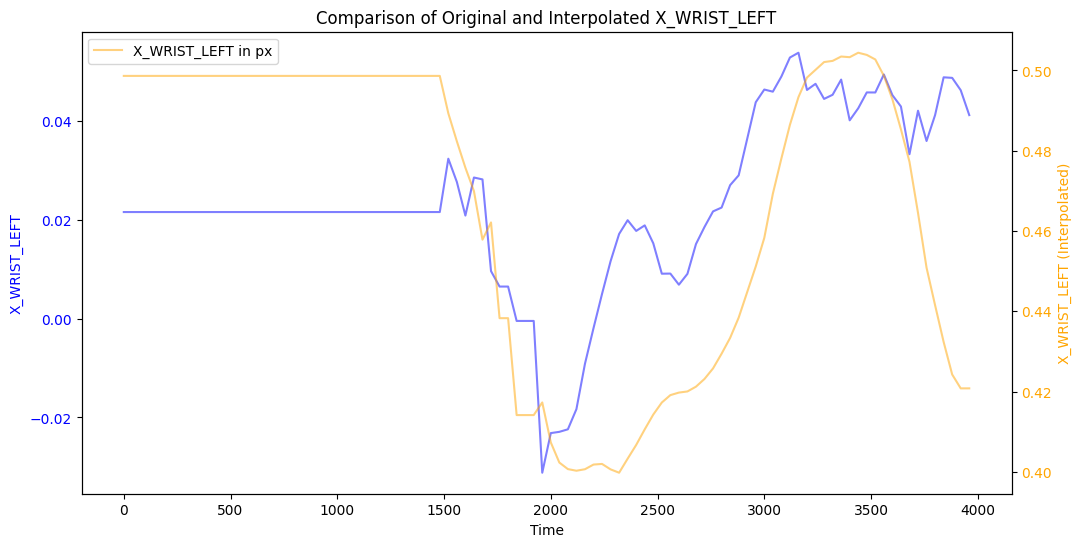

In [118]:
# plot X_WRIST_RIGHT from df and df_px such that both have their own y axis, one on left one on right

plt.figure(figsize=(12, 6))
ax1 = plt.gca()
ax1.plot(df['time'], df['X_WRIST_LEFT']*-1, label='X_WRIST_LEFT in m', color='blue', alpha=0.5)
ax1.set_xlabel('Time')
ax1.set_ylabel('X_WRIST_LEFT', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
ax2.plot(df_px['time'], df_px['X_WRIST_LEFT'], label='X_WRIST_LEFT in px', color='orange', alpha=0.5)
ax2.set_ylabel('X_WRIST_LEFT (Interpolated)', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')
plt.title('Comparison of Original and Interpolated X_WRIST_LEFT')
plt.legend()
plt.show()
